# Lab 8: Unsupervised Pre-training in a DNN

**Roll No:** 123cs0211  
**Name:** NVSaiRaghava

**Question:** Implement the Unsupervised pre-training in a DNN.
- a) Take 10 layers
- b) Rest of the parameters are standard as before
- c) Compare the results without pre-training the DNN with same parameters

## Idea

With 10 sigmoid layers, random weights don't train well because the gradient shrinks at every layer, so the early layers barely learn.  
In unsupervised pre-training, each layer is first trained as an autoencoder (no labels) to reconstruct the output of the layer below it.  
Then all layers are stacked, a softmax layer is added and the full network is fine-tuned with labels.

## Loading MNIST

In [1]:
import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Flatten 28x28 -> 784 and normalise pixel values to [0, 1]
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 784).astype("float32") / 255.0

print(f"Training data shape: {x_train.shape}")
print(f"Test data shape:     {x_test.shape}")

Training data shape: (60000, 784)
Test data shape:     (10000, 784)


## Parameters

Same as Lab 5: sigmoid in hidden layers, softmax output, dropout 0.2, adam, sparse categorical crossentropy, 10 epochs. Only change is 10 hidden layers (128 neurons each).

In [2]:
NUM_HIDDEN_LAYERS = 10      # 10 hidden layers
HIDDEN_UNITS      = 128     # neurons per hidden layer
ACTIVATION        = "sigmoid"
DROPOUT           = 0.2
NUM_CLASSES       = 10
EPOCHS            = 10      # supervised training / fine-tuning epochs
BATCH_SIZE        = 32
VAL_SPLIT         = 0.1

# Unsupervised pre-training settings (per layer)
PRETRAIN_EPOCHS     = 5
PRETRAIN_BATCH_SIZE = 256

## Model

The same function builds both models, so the architecture is exactly the same.

In [3]:
def build_dnn(name):
    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(784,)))
    for i in range(NUM_HIDDEN_LAYERS):
        model.add(layers.Dense(HIDDEN_UNITS, activation=ACTIVATION, name=f"HL_{i+1}"))
        model.add(layers.Dropout(DROPOUT, name=f"Dropout_{i+1}"))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax", name="Output_Layer"))
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_dnn("DNN_10_Layers").summary()

Model: "DNN_10_Layers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ HL_1 (Dense)                    │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_2 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_3 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_4 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_5 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_6 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_7 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_8 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_9 (Dense)                    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HL_10 (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250,378 (978.04 KB)

 Trainable params: 250,378 (978.04 KB)

 Non-trainable params: 0 (0.00 B)

## Model 1: Without pre-training

Weights are randomly initialised and the model is directly trained on the labels.

In [4]:
tf.random.set_seed(SEED)
model_no_pt = build_dnn("DNN_No_Pretraining")

start = time.time()
hist_no_pt = model_no_pt.fit(x_train, y_train,
                             epochs=EPOCHS, batch_size=BATCH_SIZE,
                             validation_split=VAL_SPLIT, verbose=2)
time_no_pt = time.time() - start
print(f"\nTraining time: {time_no_pt:.1f} s")

Epoch 1/10


1688/1688 - 27s - 16ms/step - accuracy: 0.1042 - loss: 2.3126 - val_accuracy: 0.1050 - val_loss: 2.3017


Epoch 2/10


1688/1688 - 19s - 11ms/step - accuracy: 0.1126 - loss: 2.3019 - val_accuracy: 0.1050 - val_loss: 2.3019


Epoch 3/10


...

Epoch 9/10


1688/1688 - 15s - 9ms/step - accuracy: 0.1132 - loss: 2.3013 - val_accuracy: 0.1050 - val_loss: 2.3021


Epoch 10/10


1688/1688 - 15s - 9ms/step - accuracy: 0.1132 - loss: 2.3013 - val_accuracy: 0.1050 - val_loss: 2.3020



Training time: 168.4 s


## Model 2: With unsupervised pre-training

### Step 1: Layer-wise pre-training using autoencoders

Each layer is trained as an autoencoder to reconstruct its own input (MSE loss, no labels).  
Its encoder weights are saved and its output becomes the input for the next layer.

In [5]:
tf.random.set_seed(SEED)

pretrained_weights = []          # (W, b) of each trained encoder
pretrain_losses    = []          # final reconstruction loss of each layer
h = x_train                      # h_0 = raw input (labels are NOT used)

start = time.time()
for k in range(NUM_HIDDEN_LAYERS):
    input_dim = h.shape[1]
    encoder = layers.Dense(HIDDEN_UNITS, activation=ACTIVATION, name=f"enc_{k+1}")
    decoder = layers.Dense(input_dim, activation="sigmoid", name=f"dec_{k+1}")

    inp = layers.Input(shape=(input_dim,))
    autoencoder = models.Model(inp, decoder(encoder(inp)), name=f"AE_{k+1}")
    autoencoder.compile(optimizer="adam", loss="mse")

    hist = autoencoder.fit(h, h, epochs=PRETRAIN_EPOCHS,
                           batch_size=PRETRAIN_BATCH_SIZE, verbose=0)
    loss = hist.history["loss"][-1]
    pretrain_losses.append(loss)
    pretrained_weights.append(encoder.get_weights())

    # Representation that feeds the next autoencoder
    h = encoder(h).numpy()
    print(f"Layer {k+1:2d}: input dim = {input_dim:3d} -> {HIDDEN_UNITS}, "
          f"reconstruction MSE = {loss:.5f}")

time_pretrain = time.time() - start
print(f"\nUnsupervised pre-training time: {time_pretrain:.1f} s")

Layer  1: input dim = 784 -> 128, reconstruction MSE = 0.02180


Layer  2: input dim = 128 -> 128, reconstruction MSE = 0.00835


Layer  3: input dim = 128 -> 128, reconstruction MSE = 0.00247


Layer  4: input dim = 128 -> 128, reconstruction MSE = 0.00143


Layer  5: input dim = 128 -> 128, reconstruction MSE = 0.00119


Layer  6: input dim = 128 -> 128, reconstruction MSE = 0.00116


Layer  7: input dim = 128 -> 128, reconstruction MSE = 0.00121


Layer  8: input dim = 128 -> 128, reconstruction MSE = 0.00107


Layer  9: input dim = 128 -> 128, reconstruction MSE = 0.00100


Layer 10: input dim = 128 -> 128, reconstruction MSE = 0.00099

Unsupervised pre-training time: 99.7 s


### Step 2: Fine-tuning

The saved encoder weights are loaded into the 10 hidden layers and the model is trained on labels with the same settings as Model 1.

In [6]:
tf.random.set_seed(SEED)
model_pt = build_dnn("DNN_With_Pretraining")

for k, (W, b) in enumerate(pretrained_weights):
    model_pt.get_layer(f"HL_{k+1}").set_weights([W, b])
print("Loaded pre-trained weights into HL_1 ... HL_10")

start = time.time()
hist_pt = model_pt.fit(x_train, y_train,
                       epochs=EPOCHS, batch_size=BATCH_SIZE,
                       validation_split=VAL_SPLIT, verbose=2)
time_pt = time.time() - start
print(f"\nFine-tuning time: {time_pt:.1f} s")

Loaded pre-trained weights into HL_1 ... HL_10
Epoch 1/10


1688/1688 - 25s - 15ms/step - accuracy: 0.7406 - loss: 0.8330 - val_accuracy: 0.9338 - val_loss: 0.2548


Epoch 2/10


1688/1688 - 15s - 9ms/step - accuracy: 0.8909 - loss: 0.4196 - val_accuracy: 0.9492 - val_loss: 0.2019


Epoch 3/10


...

Epoch 9/10


1688/1688 - 11s - 6ms/step - accuracy: 0.9533 - loss: 0.1843 - val_accuracy: 0.9728 - val_loss: 0.1142


Epoch 10/10


1688/1688 - 26s - 15ms/step - accuracy: 0.9560 - loss: 0.1741 - val_accuracy: 0.9762 - val_loss: 0.1011



Fine-tuning time: 171.6 s


## Test results

In [7]:
loss_no_pt, acc_no_pt = model_no_pt.evaluate(x_test, y_test, verbose=0)
loss_pt,    acc_pt    = model_pt.evaluate(x_test, y_test, verbose=0)

print(f"{'Model':<32}{'Test Loss':>12}{'Test Acc':>12}{'Train time (s)':>18}")
print("-" * 74)
print(f"{'Without pre-training':<32}{loss_no_pt:>12.4f}{acc_no_pt:>12.4f}{time_no_pt:>18.1f}")
print(f"{'With unsupervised pre-training':<32}{loss_pt:>12.4f}{acc_pt:>12.4f}"
      f"{time_pretrain + time_pt:>18.1f}  (pre-train {time_pretrain:.1f} + fine-tune {time_pt:.1f})")

Model                              Test Loss    Test Acc    Train time (s)
--------------------------------------------------------------------------
Without pre-training                  2.3010      0.1135             168.4
With unsupervised pre-training        0.1325      0.9676             271.3  (pre-train 99.7 + fine-tune 171.6)


## Training curves

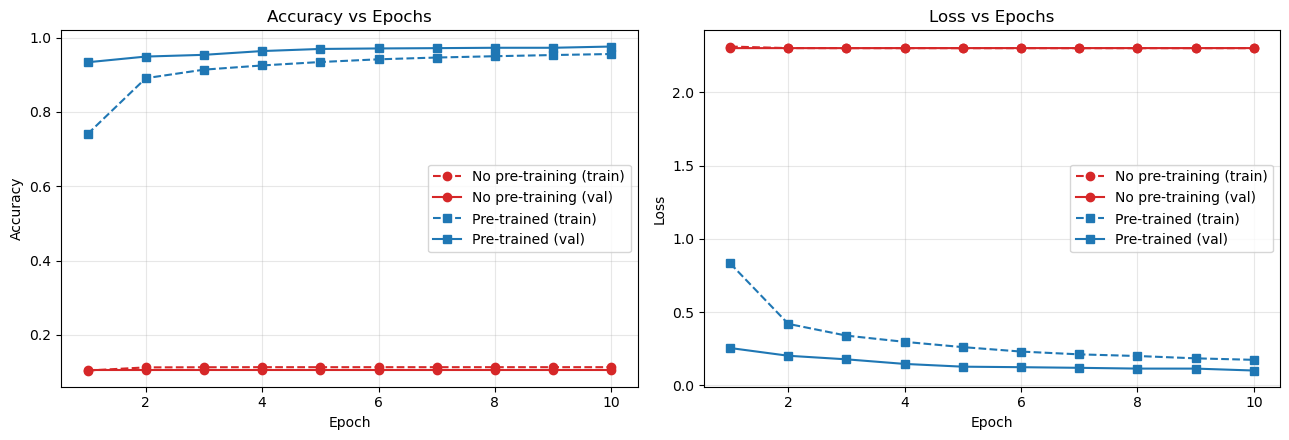

In [8]:
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(ep, hist_no_pt.history["accuracy"],     "o--", color="tab:red",  label="No pre-training (train)")
axes[0].plot(ep, hist_no_pt.history["val_accuracy"], "o-",  color="tab:red",  label="No pre-training (val)")
axes[0].plot(ep, hist_pt.history["accuracy"],        "s--", color="tab:blue", label="Pre-trained (train)")
axes[0].plot(ep, hist_pt.history["val_accuracy"],    "s-",  color="tab:blue", label="Pre-trained (val)")
axes[0].set_title("Accuracy vs Epochs")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(ep, hist_no_pt.history["loss"],     "o--", color="tab:red",  label="No pre-training (train)")
axes[1].plot(ep, hist_no_pt.history["val_loss"], "o-",  color="tab:red",  label="No pre-training (val)")
axes[1].plot(ep, hist_pt.history["loss"],        "s--", color="tab:blue", label="Pre-trained (train)")
axes[1].plot(ep, hist_pt.history["val_loss"],    "s-",  color="tab:blue", label="Pre-trained (val)")
axes[1].set_title("Loss vs Epochs")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3); axes[1].legend()

plt.tight_layout()
plt.show()

## Observations

| Model | Test Accuracy | Test Loss |
|---|---|---|
| Without pre-training | 11.35% | 2.3010 |
| With pre-training | 96.76% | 0.1325 |

- Without pre-training the model got stuck at ~11% accuracy (just guessing) and the loss stayed at 2.30.
- With pre-training it reached 96.76% test accuracy using the same parameters.
- Reason: with 10 sigmoid layers the gradient vanishes before it reaches the first layers. Pre-training gives every layer good starting weights, so they can learn.
- So unsupervised pre-training helps a lot when training deep sigmoid networks.